IMPORTING THE BASIC LIBRARIES FOR MATH AND LHS

In [111]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# Default figure font styling
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 11,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'axes.titlesize': 11,
    'axes.labelsize': 11,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 11,
    'figure.titleweight': 'bold',
    'axes.prop_cycle': cycler(color=['black'] * 4, linestyle=['-', '--', ':', '-.']),
    'axes.grid': True,
    'grid.color': '0.7',
    'grid.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'axes.linewidth': 1.0,
    'xtick.top': True,
    'ytick.right': True,
    'legend.frameon': False,
    'lines.linewidth': 1.5,
    'figure.facecolor': 'white',
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'axes.facecolor': 'white',
})

def figure_legend(ax, ncol=3):
    """Place a frameless legend above the axes."""
    return ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02),
                     ncol=ncol, frameon=False)

rng = np.random.default_rng(2026)


DEFINING THE PHYSICS BASED MODEL

In [112]:
import numpy as np

def physics_model(x, theta, mass=1.0, gravity=9.81):
    """Predict distance fallen with linear drag. x is time here"""
    x = np.asarray(x, dtype=float)

    if theta <= 0:
        raise ValueError("Theta (drag coefficient) must be positive.")
    if mass <= 0:
        raise ValueError("Mass must be positive.")
    if np.any(x < 0):
        raise ValueError("Time values must be non-negative.")

    tau = mass / theta
    y = gravity * tau * (x + tau * np.expm1(-x / tau))

    return y

GENERATING LHS SAMPLES FOR X AND THETA, AND FEEDING INTO THE PHYSICS BASED MODEL TO GENERATED SIMULATED Y. 

In [113]:
from scipy.stats import qmc

# Number of simulation runs
n_sim = 100

# Bounds for x (time) and theta (drag coefficient)
lower_bounds = [0.0, 0.2]
upper_bounds = [1.2, 2.0]

# Generate LHS samples for both inputs
sampler = qmc.LatinHypercube(d=2, seed=2026)
samples_unit = sampler.random(n=n_sim)

# Scale samples to their physical ranges
samples = qmc.scale(samples_unit, lower_bounds, upper_bounds)

x_sim = samples[:, 0]
theta_sim = samples[:, 1]

# Evaluate each (x, theta) pair
# A loop is used because physics_model checks one theta at a time.
y_sim = np.array([
    physics_model(x, theta)
    for x, theta in zip(x_sim, theta_sim)
])

print("x_sim shape:", x_sim.shape)
print("theta_sim shape:", theta_sim.shape)
print("y_sim shape:", y_sim.shape)

print("\nFirst five (x, theta, y) values:")
print(np.column_stack((x_sim, theta_sim, y_sim))[:5])

x_sim shape: (100,)
theta_sim shape: (100,)
y_sim shape: (100,)

First five (x, theta, y) values:
[[0.46585278 0.44048156 0.99525415]
 [0.10239278 1.21933099 0.0493504 ]
 [1.09974099 0.99577067 4.2502453 ]
 [0.19313827 0.32280764 0.1792243 ]
 [0.04016658 0.96863055 0.00781186]]


CREATING ALL MEASURED DATA

In [114]:
#CREATING observed x
x_obs = np.linspace(0.15,1.15,10) #this creates 10 observed x values between 0.15 and 1.15

theta_true = 0.8 #defining the true simulator value for theta. 

y_sim_obs = physics_model(x_obs, theta_true) #this is the observed y values for the observed x values.
y_sim_true = physics_model(x_obs, theta_true)

delta_true = 0.15 * x_obs**2 # defining model discrepancy. 


Generating measurement noise

In [115]:
rng = np.random.default_rng(2026)
sigma_obs = 0.05 #5% gaussian noise

noise = rng.normal(0.0,sigma_obs,size=len(x_obs))

"""This simulates sensor uncertainty:
- 0.0 is the mean noise.
- sigma_obs = 0.05 m is the noise standard deviation.
- size=len(x_obs) generates one random noise value for each observation.
The discrepancy is a systematic pattern; noise is the random variation in individual measurements."""

'This simulates sensor uncertainty:\n- 0.0 is the mean noise.\n- sigma_obs = 0.05 m is the noise standard deviation.\n- size=len(x_obs) generates one random noise value for each observation.\nThe discrepancy is a systematic pattern; noise is the random variation in individual measurements.'

In [116]:
y_obs = y_sim_true + delta_true + noise

In [117]:
# Pick one observation at random
i = rng.integers(len(x_obs))

print(f"Observation time:     {x_obs[i]:7.2f} s")
print(f"Simulator prediction: {y_sim_true[i]:7.2f} m")
print(f"Model discrepancy:    {delta_true[i]:+7.2f} m")
print(f"Measurement noise:    {noise[i]:+7.2f} m")
print("                      -------")
print(f"Observed distance:    {y_obs[i]:7.2f} m")

Observation time:        0.26 s
Simulator prediction:    0.31 m
Model discrepancy:      +0.01 m
Measurement noise:      +0.01 m
                      -------
Observed distance:       0.33 m


Normalizing and standardizing the inputs and outputs. 

In [118]:
# GP inputs: normalized x and theta
X_gp = samples_unit

# Standardize simulator outputs
y_mean = np.mean(y_sim)
y_std = np.std(y_sim)

y_gp = (y_sim - y_mean) / y_std

print("Input shape:", X_gp.shape)
print("Output shape:", y_gp.shape)
print("Output mean:", np.mean(y_gp))
print("Output standard deviation:", np.std(y_gp))

Input shape: (100, 2)
Output shape: (100,)
Output mean: -2.731148640577885e-16
Output standard deviation: 0.9999999999999999


Splitting data into training and testing data. Note its a forward emulator for regression so we will need holdout x 

In [119]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    samples_unit,
    y_sim,
    test_size=0.2,
    random_state=2026
)

# Calculate scaling using training outputs only
y_mean = np.mean(y_train_raw)
y_std = np.std(y_train_raw)

y_train = (y_train_raw - y_mean) / y_std
y_test = (y_test_raw - y_mean) / y_std

print("Training inputs:", X_train.shape)
print("Testing inputs:", X_test.shape)

Training inputs: (80, 2)
Testing inputs: (20, 2)


Defining the GP emulator and its hyperparameters, and kernel

In [120]:
# Initial GP hyperparameters
lengthscale = np.array([1.0, 1.0])  # one each for x and theta
signal_variance = 1.0

# Small diagonal term for numerical stability - nugget
alpha = 1e-8

# RBF covariance function
def rbf_kernel(X1, X2, lengthscale, signal_variance):
    # Scale each input column by its length scale
    X1_scaled = X1 / lengthscale
    X2_scaled = X2 / lengthscale

    # Squared distance between every pair of input points
    squared_distance = np.sum(
        (X1_scaled[:, None, :] - X2_scaled[None, :, :])**2,
        axis=2
    )

    return signal_variance * np.exp(-0.5 * squared_distance)

CONSTRUCTING THE GP COVARIANCE MATRIX

In [121]:
# Covariance between all pairs of training points
K = rbf_kernel(
    X_train,
    X_train,
    lengthscale,
    signal_variance
)

# Add numerical jitter to the diagonal - adding nugget to the diagonals. 
K = K + alpha * np.eye(len(X_train))

print("Covariance matrix shape:", K.shape)

Covariance matrix shape: (80, 80)


Defining the GP log likelihood

In [122]:
def gp_log_likelihood(X, y, lengthscale, signal_variance, alpha=1e-8):
    # Build the covariance matrix and add jitter
    K = rbf_kernel(X, X, lengthscale, signal_variance)
    K = K + alpha * np.eye(len(X))

    # Cholesky decomposition: K = L @ L.T
    L = np.linalg.cholesky(K)

    # Solve K⁻¹y without explicitly calculating the inverse
    v = np.linalg.solve(L, y)
    K_inv_y = np.linalg.solve(L.T, v)

    log_likelihood = (
        -0.5 * y @ K_inv_y
        - np.sum(np.log(np.diag(L)))
        - 0.5 * len(y) * np.log(2 * np.pi)
    )

    return log_likelihood


# Evaluate it at our initial hyperparameter values
log_likelihood = gp_log_likelihood(
    X_train,
    y_train,
    lengthscale,
    signal_variance,
    alpha
)

print("Initial GP log likelihood:", log_likelihood)

Initial GP log likelihood: 243.56245566166308


defining the prior distributions

In [123]:
from scipy.stats import lognorm

def log_prior(lengthscale, signal_variance):
    if np.any(lengthscale <= 0) or signal_variance <= 0:
        return -np.inf

    # Log-normal priors, each with median 1.0
    log_p_lengthscale = np.sum(
        lognorm.logpdf(lengthscale, s=1.0, scale=1.0)
    )

    log_p_variance = lognorm.logpdf(
        signal_variance, s=1.0, scale=1.0
    )

    return log_p_lengthscale + log_p_variance


print("Initial log prior:", log_prior(lengthscale, signal_variance))

Initial log prior: -2.756815599614018


Combining prior and likelihood to generate the posterior

In [124]:
def log_posterior(X, y, lengthscale, signal_variance):
    # Check whether the hyperparameters are plausible under the priors
    lp = log_prior(lengthscale, signal_variance)

    if not np.isfinite(lp):
        return -np.inf

    # Evaluate how well they explain the simulator data
    ll = gp_log_likelihood(
        X,
        y,
        lengthscale,
        signal_variance
    )

    return lp + ll


print(
    "Initial log posterior:",
    log_posterior(X_train, y_train, lengthscale, signal_variance)
)

Initial log posterior: 240.80564006204906


Building MCMC sampler

In [125]:
rng = np.random.default_rng(2026)

def log_posterior_log_scale(z):
    # Convert log parameters back to their original positive scale
    params = np.exp(z)

    lengthscale = params[:2]
    signal_variance = params[2]

    try:
        lp = log_posterior(
            X_train, y_train, lengthscale, signal_variance
        )
    except np.linalg.LinAlgError:
        return -np.inf

    # Change-of-variables adjustment
    return lp + np.sum(z)


n_steps = 30000
burn_in = 5000  # Adapt the proposal during these initial iterations
adapt_start = 100
adapt_interval = 100
n_params = 3
proposal_cov = 0.1**2 * np.eye(n_params)

# Starting values: [lengthscale_x, lengthscale_theta, signal_variance]
z = np.log([1.0, 1.0, 1.0])
current_logp = log_posterior_log_scale(z)

log_samples = np.zeros((n_steps, n_params))
accepted = np.zeros(n_steps, dtype=bool)

for i in range(n_steps):
    z_proposed = rng.multivariate_normal(z, proposal_cov)
    proposed_logp = log_posterior_log_scale(z_proposed)

    if np.log(rng.uniform()) < proposed_logp - current_logp:
        z = z_proposed
        current_logp = proposed_logp
        accepted[i] = True

    # Include repeated states after rejected proposals in the covariance.
    log_samples[i] = z

    # Estimate covariance in log space; freeze it after burn-in.
    if i + 1 >= adapt_start and i + 1 <= burn_in and (i + 1) % adapt_interval == 0:
        empirical_cov = np.cov(log_samples[:i + 1], rowvar=False)
        proposal_cov = (2.38**2 / n_params) * (empirical_cov + 1e-6 * np.eye(n_params))

samples = np.exp(log_samples)  # Full chain, useful for trace plots
posterior_samples = samples[burn_in:]

print("Burn-in iterations:", burn_in)
print("Posterior samples shape:", posterior_samples.shape)
print("Burn-in acceptance rate:", accepted[:burn_in].mean())
print("Post-burn-in acceptance rate:", accepted[burn_in:].mean())

Burn-in iterations: 5000
Posterior samples shape: (25000, 3)
Burn-in acceptance rate: 0.2352
Post-burn-in acceptance rate: 0.27196


Generating MCMC traceplots

C:\Users\panchal\AppData\Local\Temp\ipykernel_44340\3829017958.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  return ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02),


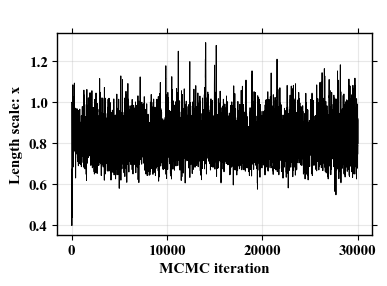

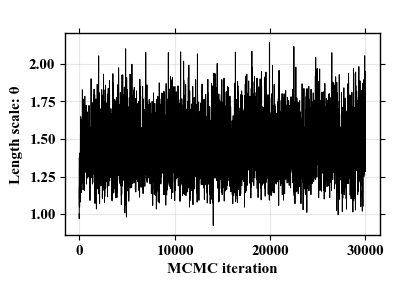

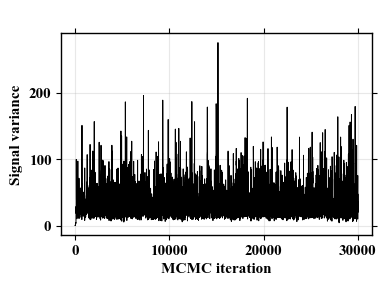

In [126]:
parameter_names = [
    "Length scale: x",
    "Length scale: θ",
    "Signal variance"
]

for j in range(3):
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(samples[:, j], linewidth=0.7)
    ax.set_ylabel(parameter_names[j])
    ax.set_xlabel("MCMC iteration")
    ax.grid(alpha=0.3)
    figure_legend(ax)
    fig.tight_layout()
    plt.show()

Plotting prior, truth and posterior curves FOR REGRESSION ONLY

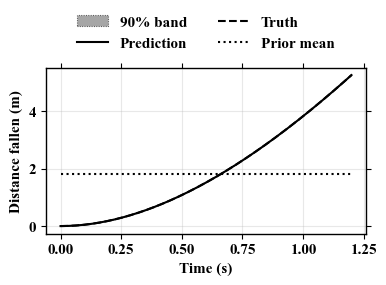

In [127]:
from scipy.linalg import solve_triangular

# Time points for the prediction curve
x_plot = np.linspace(0.0, 1.2, 150)

# Hold theta fixed to evaluate the emulator
theta_plot = theta_true

# Put prediction inputs on the same 0–1 scale as X_train
X_plot_physical = np.column_stack((
    x_plot,
    np.full_like(x_plot, theta_plot)
))

X_plot = qmc.scale(
    X_plot_physical,
    lower_bounds,
    upper_bounds,
    reverse=True
)

# Use up to 200 posterior hyperparameter samples
rng_predict = np.random.default_rng(123)
n_draws = min(200, len(posterior_samples))

indices = rng_predict.choice(
    len(posterior_samples),
    size=n_draws,
    replace=False
)

predictive_draws = []

for idx in indices:
    ls = posterior_samples[idx, :2]
    variance = posterior_samples[idx, 2]

    # Training covariance and covariance with prediction points
    K = rbf_kernel(X_train, X_train, ls, variance)
    K += alpha * np.eye(len(X_train))

    K_cross = rbf_kernel(X_train, X_plot, ls, variance)

    # Conditional GP mean and joint covariance across time points
    L = np.linalg.cholesky(K)
    v = solve_triangular(L, K_cross, lower=True)
    w = solve_triangular(L, y_train, lower=True)

    pred_mean = v.T @ w
    pred_cov = rbf_kernel(X_plot, X_plot, ls, variance) - v.T @ v
    pred_cov = (pred_cov + pred_cov.T) / 2  # Remove roundoff asymmetry

    # Draw one correlated curve; clip only numerical negative eigenvalues.
    eigenvalues, eigenvectors = np.linalg.eigh(pred_cov)
    tolerance = 1e-8 * max(variance, 1.0)
    if eigenvalues.min() < -tolerance:
        raise ValueError('Predictive covariance is not positive semidefinite')
    draw = pred_mean + eigenvectors @ (
        np.sqrt(np.maximum(eigenvalues, 0.0)) * rng_predict.normal(size=len(x_plot))
    )
    predictive_draws.append(draw)

# Convert standardized GP outputs back to meters
predictive_draws = np.asarray(predictive_draws) * y_std + y_mean

prediction = np.mean(predictive_draws, axis=0)
# Pointwise percentiles of the jointly sampled curves (not a simultaneous band).
lower, upper = np.percentile(predictive_draws, [5, 95], axis=0)

# Known simulator truth, available because this is synthetic data
truth = physics_model(x_plot, theta_plot)

# A zero-mean GP in standardized units has prior mean y_mean in meters
prior_prediction = np.full_like(x_plot, y_mean)

fig, ax = plt.subplots(figsize=(4, 3))

ax.fill_between(
    x_plot, lower, upper,
    facecolor="0.65", edgecolor="0.3", linestyle=":", linewidth=0.8,
    label="90% band"
)
ax.plot(x_plot, prediction, "k-", label="Prediction")
ax.plot(x_plot, truth, "k--", label="Truth")
ax.plot(x_plot, prior_prediction, "k:", label="Prior mean")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Distance fallen (m)")
figure_legend(ax, ncol=2)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Freezing the trained GP emulator

In [128]:
# Freeze the trained emulator at posterior median hyperparameters
frozen_parameters = np.median(posterior_samples, axis=0)

frozen_lengthscale = frozen_parameters[:2]
frozen_signal_variance = frozen_parameters[2]

# Precompute the frozen training covariance
K_frozen = rbf_kernel(
    X_train,
    X_train,
    frozen_lengthscale,
    frozen_signal_variance
)

K_frozen += alpha * np.eye(len(X_train))
L_frozen = np.linalg.cholesky(K_frozen)

print("Frozen lengthscale:", frozen_lengthscale)
print("Frozen signal variance:", frozen_signal_variance)

Frozen lengthscale: [0.81566901 1.45272637]
Frozen signal variance: 29.40574157227082


Prediction function for the frozen emulator

In [129]:
def frozen_emulator_predict(x, theta):
    x = np.asarray(x, dtype=float)

    # Construct physical inputs [x, theta]
    X_new_physical = np.column_stack([
        x,
        np.full(x.size, theta)
    ])

    # Apply the same normalization used for the LHS design
    X_new = qmc.scale(
        X_new_physical,
        lower_bounds,
        upper_bounds,
        reverse=True
    )

    # Covariances using frozen hyperparameters
    K_cross = rbf_kernel(
        X_train, X_new,
        frozen_lengthscale,
        frozen_signal_variance
    )

    K_new = rbf_kernel(
        X_new, X_new,
        frozen_lengthscale,
        frozen_signal_variance
    )

    # Conditional GP mean and covariance
    v = np.linalg.solve(L_frozen, K_cross)
    weights = np.linalg.solve(L_frozen, y_train)

    mean_standardized = v.T @ weights
    covariance_standardized = K_new - v.T @ v

    # Convert predictions back to physical output units
    mean = y_mean + y_std * mean_standardized
    covariance = y_std**2 * covariance_standardized

    return mean, covariance

Discrepancy GP defined below. 

In [130]:
def discrepancy_kernel(
    x1,
    x2,
    discrepancy_lengthscale,
    discrepancy_signal_variance
):
    x1 = np.asarray(x1, dtype=float)
    x2 = np.asarray(x2, dtype=float)

    # Normalize x using the simulator x bounds
    x_min, x_max = lower_bounds[0], upper_bounds[0]

    x1_scaled = (x1 - x_min) / (x_max - x_min)
    x2_scaled = (x2 - x_min) / (x_max - x_min)

    # Pairwise squared distances
    squared_distance = (
        x1_scaled[:, None] - x2_scaled[None, :]
    )**2

    return discrepancy_signal_variance * np.exp(
        -0.5 * squared_distance / discrepancy_lengthscale**2
    )

Defining the calibration likelihood

In [131]:
def calibration_log_likelihood(
    theta,
    discrepancy_lengthscale,
    discrepancy_signal_variance
):
    # Frozen-emulator prediction at the observation locations
    emulator_mean, emulator_covariance = frozen_emulator_predict(
        x_obs,
        theta
    )

    # Discrepancy covariance
    discrepancy_covariance = discrepancy_kernel(
        x_obs,
        x_obs,
        discrepancy_lengthscale,
        discrepancy_signal_variance
    )

    # Total uncertainty:
    # emulator + discrepancy + measurement noise
    total_covariance = (
        emulator_covariance
        + discrepancy_covariance
        + sigma_obs**2 * np.eye(len(x_obs))
        + 1e-8 * np.eye(len(x_obs))
    )

    residual = y_obs - emulator_mean

    try:
        L = np.linalg.cholesky(total_covariance)
    except np.linalg.LinAlgError:
        return -np.inf

    solved_residual = np.linalg.solve(L, residual)

    log_likelihood = (
        -0.5 * solved_residual @ solved_residual
        - np.sum(np.log(np.diag(L)))
        - 0.5 * len(y_obs) * np.log(2 * np.pi)
    )

    return log_likelihood

Defining priors for theta and discrepancy. 

In [132]:
from scipy.stats import lognorm

# Prior median for discrepancy variance in physical output units
discrepancy_variance_scale = (0.10 * y_std)**2

def calibration_log_prior(
    theta,
    discrepancy_lengthscale,
    discrepancy_signal_variance
):
    # Use the same theta bounds as the simulator design.
    theta_min, theta_max = lower_bounds[1], upper_bounds[1]
    # Uniform prior for theta within its physical bounds
    if not theta_min <= theta <= theta_max:
        return -np.inf

    if discrepancy_lengthscale <= 0:
        return -np.inf

    if discrepancy_signal_variance <= 0:
        return -np.inf

    log_prior_theta = -np.log(theta_max - theta_min)

    # Smooth discrepancy prior on normalized x
    log_prior_lengthscale = lognorm.logpdf(
        discrepancy_lengthscale,
        s=0.5,
        scale=0.5
    )

    # Prior favoring a relatively small discrepancy
    log_prior_variance = lognorm.logpdf(
        discrepancy_signal_variance,
        s=0.7,
        scale=discrepancy_variance_scale
    )

    return (
        log_prior_theta
        + log_prior_lengthscale
        + log_prior_variance
    )

Combining calibration prior and posterior into log posterior 

In [133]:
def calibration_log_posterior(
    theta,
    discrepancy_lengthscale,
    discrepancy_signal_variance
):
    log_prior_value = calibration_log_prior(
        theta,
        discrepancy_lengthscale,
        discrepancy_signal_variance
    )

    if not np.isfinite(log_prior_value):
        return -np.inf

    log_likelihood_value = calibration_log_likelihood(
        theta,
        discrepancy_lengthscale,
        discrepancy_signal_variance
    )

    return log_prior_value + log_likelihood_value


# Initial calibration values
initial_theta = 1.0
initial_discrepancy_lengthscale = 0.5
initial_discrepancy_signal_variance = discrepancy_variance_scale

initial_log_posterior = calibration_log_posterior(
    initial_theta,
    initial_discrepancy_lengthscale,
    initial_discrepancy_signal_variance
)

print("Initial calibration log posterior:", initial_log_posterior)

Initial calibration log posterior: 10.299682068233237


Running MCMC for theta and 2 delta GP parameters

In [135]:
rng_calibration = np.random.default_rng(2027)

def transformed_calibration_log_posterior(z):
    theta = z[0]
    discrepancy_lengthscale = np.exp(z[1])
    discrepancy_signal_variance = np.exp(z[2])

    value = calibration_log_posterior(
        theta,
        discrepancy_lengthscale,
        discrepancy_signal_variance
    )

    if not np.isfinite(value):
        return -np.inf

    # Jacobian for the two log-transformed parameters
    return value + z[1] + z[2]


n_calibration_steps = 30000
calibration_burn_in = 5000  # Discard the initial iterations from posterior summaries

# Proposal SDs for:
# theta, log discrepancy lengthscale, log discrepancy variance
proposal_sd = np.array([0.05, 0.10, 0.10])

current_z = np.array([
    initial_theta,
    np.log(initial_discrepancy_lengthscale),
    np.log(initial_discrepancy_signal_variance)
])

current_log_posterior = transformed_calibration_log_posterior(current_z)

calibration_samples = np.zeros((n_calibration_steps, 3))
accepted = 0

for i in range(n_calibration_steps):
    proposed_z = current_z + rng_calibration.normal(
        0.0,
        proposal_sd,
        size=3
    )

    proposed_log_posterior = (
        transformed_calibration_log_posterior(proposed_z)
    )

    log_acceptance_ratio = (
        proposed_log_posterior - current_log_posterior
    )

    if np.log(rng_calibration.uniform()) < log_acceptance_ratio:
        current_z = proposed_z
        current_log_posterior = proposed_log_posterior
        accepted += 1

    calibration_samples[i] = [
        current_z[0],
        np.exp(current_z[1]),
        np.exp(current_z[2])
    ]

calibration_posterior_samples = calibration_samples[calibration_burn_in:]

print("Burn-in iterations:", calibration_burn_in)
print("Posterior samples shape:", calibration_posterior_samples.shape)
print("Acceptance rate:", accepted / n_calibration_steps)
print("Sample columns: theta, discrepancy lengthscale, discrepancy variance")

Burn-in iterations: 5000
Posterior samples shape: (25000, 3)
Acceptance rate: 0.7165333333333334
Sample columns: theta, discrepancy lengthscale, discrepancy variance


C:\Users\panchal\AppData\Local\Temp\ipykernel_44340\3829017958.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  return ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02),


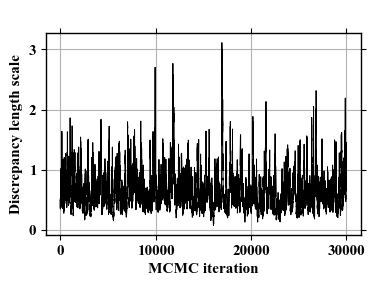

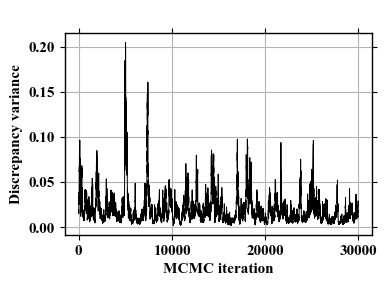

In [137]:
# Trace plots for the discrepancy GP parameters
parameter_labels = ['Discrepancy length scale', 'Discrepancy variance']
iterations = np.arange(1, len(calibration_samples) + 1)

for column, label in zip([1, 2], parameter_labels):
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(iterations, calibration_samples[:, column], color='black', linewidth=0.7)
    ax.set_xlabel('MCMC iteration')
    ax.set_ylabel(label)
    figure_legend(ax)
    fig.tight_layout()
    plt.show()

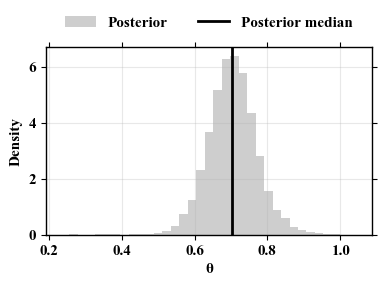

In [141]:
theta_posterior = calibration_posterior_samples[:, 0]
theta_min, theta_max = lower_bounds[1], upper_bounds[1]

theta_grid = np.linspace(theta_min, theta_max, 300)
theta_prior_density = np.full_like(
    theta_grid,
    1.0 / (theta_max - theta_min)
)


fig, ax = plt.subplots(figsize=(4, 3))


plt.hist(
    theta_posterior,
    bins=35,
    density=True,
    alpha=0.55,
    color="0.65",
    label="Posterior"
)


plt.axvline(
    theta_median,
    color="black",
    linewidth=2,
    label="Posterior median"
)


plt.xlabel("θ")
plt.ylabel("Density")
figure_legend(ax, ncol=2)
plt.grid(alpha=0.3)
fig.tight_layout()
plt.show()

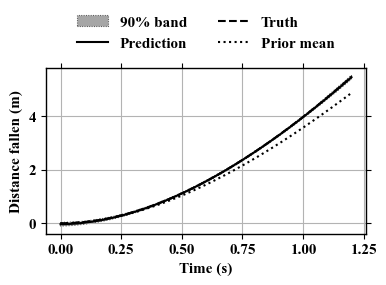

In [142]:
# Posterior prediction for the latent physical response y(x)
from scipy.linalg import solve_triangular

x_y = np.linspace(lower_bounds[0], upper_bounds[0], 150)
x_joint = np.concatenate((x_obs, x_y))
n_obs = len(x_obs)
rng_y = np.random.default_rng(2028)
n_y_draws = min(200, len(calibration_posterior_samples))
draw_indices = rng_y.choice(len(calibration_posterior_samples), n_y_draws, replace=False)
y_draws = []

for index in draw_indices:
    theta, delta_length, delta_variance = calibration_posterior_samples[index]
    mean_joint, cov_emulator = frozen_emulator_predict(x_joint, theta)
    cov_joint = cov_emulator + discrepancy_kernel(x_joint, x_joint, delta_length, delta_variance)
    cov_obs = cov_joint[:n_obs, :n_obs] + (sigma_obs**2 + 1e-8) * np.eye(n_obs)
    cov_cross = cov_joint[:n_obs, n_obs:]
    L_obs = np.linalg.cholesky(cov_obs)
    residual = solve_triangular(L_obs, y_obs - mean_joint[:n_obs], lower=True)
    v = solve_triangular(L_obs, cov_cross, lower=True)
    mean_y = mean_joint[n_obs:] + v.T @ residual
    cov_y = cov_joint[n_obs:, n_obs:] - v.T @ v
    cov_y = (cov_y + cov_y.T) / 2
    eigenvalues, eigenvectors = np.linalg.eigh(cov_y)
    tolerance = 1e-8 * max(1.0, np.max(np.abs(np.diag(cov_joint))))
    if eigenvalues.min() < -tolerance:
        raise ValueError('Predictive covariance is not positive semidefinite')
    y_draws.append(mean_y + eigenvectors @ (np.sqrt(np.maximum(eigenvalues, 0)) * rng_y.normal(size=len(x_y))))

y_draws = np.asarray(y_draws)
y_prediction = y_draws.mean(axis=0)
y_lower, y_upper = np.percentile(y_draws, [5, 95], axis=0)

# Prior mean: average the frozen emulator over the uniform prior on θ.
theta_prior = np.linspace(lower_bounds[1], upper_bounds[1], 100)
y_prior = np.mean([frozen_emulator_predict(x_y, theta)[0] for theta in theta_prior], axis=0)
# Known synthetic physical truth: simulator plus the discrepancy used to generate data.
y_truth = physics_model(x_y, theta_true) + 0.15 * x_y**2

fig, ax = plt.subplots(figsize=(4, 3))
ax.fill_between(x_y, y_lower, y_upper, facecolor='0.65', edgecolor='0.3',
                linestyle=':', linewidth=0.8, label='90% band')
ax.plot(x_y, y_prediction, 'k-', label='Prediction')
ax.plot(x_y, y_truth, 'k--', label='Truth')
ax.plot(x_y, y_prior, 'k:', label='Prior mean')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Distance fallen (m)')
figure_legend(ax, ncol=2)
fig.tight_layout()
plt.show()